# Proyecto: STATS19 #

Proyecto para el Módulo 1 del Diplomado de Métodos Estadísticos y Matemáticos para la Ciencia de Datos, Ed. 3 (Facultad de Ciencias, UNAM).

**Integrantes del equipo:**
- Guillermo Adolfo Méndez Roche
- Sofía Quetzalli González Robles
- [Nombre completo integrante 3]
- [Nombre completo integrante 4]
- [Nombre completo integrante 5]

**Fecha:** 22 de noviembre de 2026

## 1. Introducción ##

### 1.1. Fuente de los datos ###

El presente proyecto utiliza la base de datos **STATS19**, que recopila información oficial sobre siniestros viales ocurridos en Gran Bretaña. Los datos son reportados por 44 fuerzas policiales de Escocia, Gales e Inglaterra. Cabe mencionar que únicamente se registran siniestros que cumplen las siguientes tres condiciones:

1. Haber sucedido en la vía pública.

2. Haber causado lesiones o el fallecimiento de al menos una persona.

3. Haber llegado a conocimiento de la policía en un plazo máximo de 30 días después del siniestro.

**Procedencia y condiciones de uso.** La base de datos es publicada abiertamente por el Departamento de Transporte del Reino Unido (*DfT* por sus siglas en inglés) bajo la licencia **Open Government Licence v3.0 (OGL)**, la cual permite copiar, publicar, distribuir, adaptar y analizar la información libremente con fines académicos o analíticos, siempre que se cite la fuente oficial.

La documentación completa de los datos puede consultarse en [este enlace](https://www.gov.uk/government/statistical-data-sets/road-safety-open-data).

> **Ojo** El Departamento de Transporte del Reino Unido advierte que en STATS19 existe un subregistro importante de personas que sufren lesiones no mortales en siniestros viales. En particular, es posible que una persona resulte lesionada en un siniestro registrado sin que sus lesiones queden capturadas; por lo tanto, la ausencia de un registro de lesión no implica necesariamente que la persona haya resultado ilesa.

### 1.2. Datos de STATS19 ###

Como se mencionó anteriormente, STATS19 actualiza sus datos anualmente. No obstante, para el alcance de este proyecto, trabajaremos con los datos correspondientes a los años 2023, 2024 y 2025.

Para cada año, los datos se distribuyen en tres tablas:

- `collisions`: Cada fila representa un siniestro reportado. Contiene, entre otras variables, la fecha y hora del siniestro, así como el número de vehículos involucrados.

- `vehicles`: Cada fila representa un vehículo involucrado en un siniestro. Contiene variables como el tipo de vehículo, el sexo de quien conducía la unidad y el primer punto de impacto.

- `casualties`: Cada fila representa una persona lesionada o fallecida registrada en un siniestro. Contiene la clase de víctima (conductor, pasajero o peatón), el vehículo asociado y la gravedad de sus lesiones, entre otras.

#### 1.2.1. Identificadores y relaciones entre tablas #####

- En `collisions`, cada siniestro se identifica mediante `collision_index`, una referencia alfanumérica que es, por definición, única para cada siniestro.

- En `vehicles`, cada vehículo se identifica mediante la combinación de un `collision_index` y un `vehicle_reference`.

- En `casualties`, cada víctima se identifica mediante la combinación de `collision_index` y un `casualty_reference` (de manera análoga a como funcionan `collision_index` y `vehicle_reference` en el caso anterior).

  En `casualties` también aparece la columna `vehicle_reference`. Cuando la víctima es un conductor, indica la referencia que tiene el vehículo que conducía, dentro del siniestro.

Estos identificadores nos permiten cruzar información de los siniestros, los vehículos involucrados y las víctimas registradas.

#### Ejemplo de cómo se ve la tabla `vehicles` ####

A continuación incluimos un extracto de la tabla de vehículos del año 2025. Las filas del mismo color corresponden a vehículos registrados en un mismo siniestro.

Nótese que los valores de la columna `vehicle_type` son números enteros, pero la variable es **cualitativa nominal**, pues dichos códigos representan categorías de vehículos. En los tres años analizados, el código correspondiente a los automóviles es `9`.

In [ ]:
# @title
from IPython.display import HTML, display

tabla_ejemplo_html = """
<table align="center" style="text-align: center; color: #22232F; border-collapse: collapse;">
    <tr style="background-color: #FFFFFF; border-bottom: 1px solid #CCC;">
        <th style="padding: 6px 12px;">collision_index</th>
        <th style="padding: 6px 12px;">vehicle_reference</th>
        <th style="padding: 6px 12px;">vehicle_type</th>
        <th style="padding: 6px 12px;">⋯</th>
    </tr>
    <tr style="background-color: #FFE699;">
        <td style="padding: 4px 12px;">2025010551786</td>
        <td style="padding: 4px 12px;">1</td>
        <td style="padding: 4px 12px;">3</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #FFE699;">
        <td style="padding: 4px 12px;">2025010551786</td>
        <td style="padding: 4px 12px;">2</td>
        <td style="padding: 4px 12px;">9</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #DCEAF5;">
        <td style="padding: 4px 12px;">2025010551795</td>
        <td style="padding: 4px 12px;">1</td>
        <td style="padding: 4px 12px;">9</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #DCEAF5;">
        <td style="padding: 4px 12px;">2025010551795</td>
        <td style="padding: 4px 12px;">2</td>
        <td style="padding: 4px 12px;">1</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #FFE9D6;">
        <td style="padding: 4px 12px;">2025010551794</td>
        <td style="padding: 4px 12px;">1</td>
        <td style="padding: 4px 12px;">9</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #FFFFFF;">
        <td>⋮</td>
        <td>⋮</td>
        <td>⋮</td>
        <td>⋱</td>
    </tr>
</table>
"""
display(HTML(tabla_ejemplo_html))

collision_index,vehicle_reference,vehicle_type,⋯
2025010551786,1,3,⋯
2025010551786,2,9,⋯
2025010551795,1,9,⋯
2025010551795,2,1,⋯
2025010551794,1,9,⋯
⋮,⋮,⋮,⋱


### 1.3. Planteamiento del problema ###

#### 1.3.1. Preguntas conductoras ####

El análisis que realizamos en este proyecto parte de la siguiente idea:

> En siniestros con exactamente dos automóviles y conductores de distinto sexo, ¿cómo se comparan la presencia y la gravedad de las lesiones registradas de ambos conductores?

Más concretamente, responderemos las siguientes preguntas de investigación de carácter descriptivo, aunque con ciertas acotaciones que mencionaremos enseguida:

1. Si solo uno de los conductores presenta lesiones registradas, ¿existe una tendencia consistente sobre si se trata del conductor o de la conductora?

2. Si ambos conductores presentan lesiones registradas de distinta gravedad, ¿existe una tendencia sobre cuál de los dos presenta las lesiones más graves?

> **Algunas consideraciones importantes.**
Tanto la presencia como la gravedad de las lesiones podrían estar influenciadas por las condiciones físicas de cada colisión. Puesto que STATS19 no reporta variables como la masa de los vehículos o la velocidad al momento del impacto, restringiremos el análisis a siniestros en los que ambos automóviles registraron un **primer punto de impacto frontal** (`first_point_of_impact == 1`). Sin embargo es importante aclarar que esto NO significa que los automóviles hayan chocado entre sí.

## 2. Carga y exploración inicial de datos ##

### 2.1. Importación de paquetes y carga de datos ###

El siguiente bloque de código importa los paquetes que utilizaremos a lo largo de este proyecto:

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Carpeta para exportar resultados y figuras del repositorio
os.makedirs("resultados", exist_ok=True)

Por otro lado, cargamos los datos de STATS19 para los años 2023, 2024 y 2025. Nótese que se cargan una tabla de siniestros, una de vehículos y una de víctimas para cada año, dando un total de nueve tablas.

In [ ]:
# En su momento, estos datos se van a cargar desde una carpeta local (que el usuario descargará desde el repositiorio)

# Esta columna hay que modificarla cuando ya tengamos el repositorio y su estructura

# Datos de 2023

collisions_2023 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-collision-2023.csv",
    low_memory=False
)

vehicles_2023 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-vehicle-2023.csv",
    low_memory=False
)

casualties_2023 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-casualty-2023.csv",
    low_memory=False
)

# Datos de 2024

collisions_2024 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-collision-2024.csv",
    low_memory=False
)

vehicles_2024 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-vehicle-2024.csv",
    low_memory=False
)

casualties_2024 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-casualty-2024.csv",
    low_memory=False
)

# Datos de 2025

collisions_2025 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-collision-2025.csv",
    low_memory=False
)

vehicles_2025 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-vehicle-2025.csv",
    low_memory=False
)

casualties_2025 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-casualty-2025.csv",
    low_memory=False
)

print("Datos de STATS19 cargados correctamente.")

Datos de STATS19 cargados correctamente.


Como estamos trabajando con datos de tres años distintos, es conveniente dejar clara la estructura que seguiremos. Dicha estructura estará dada en un diccionario:

In [ ]:
# En este diccionario guardamos la información de STATS19 para cada año #

datos = {
    2023: {
        "collisions": collisions_2023,
        "vehicles": vehicles_2023,
        "casualties": casualties_2023
    },
    2024: {
        "collisions": collisions_2024,
        "vehicles": vehicles_2024,
        "casualties": casualties_2024
    },
    2025: {
        "collisions": collisions_2025,
        "vehicles": vehicles_2025,
        "casualties": casualties_2025
    }
}

Por ejemplo, si queremos visualizar las primeras tres filas de siniestros de 2025 podemos ejecutar el siguiente bloque de código:

In [ ]:
datos[2025]["collisions"].head(3)

,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202517M101925,2025,17M101925,447673.0,519279.0,-1.26420,54.56650,17,3,1,...,-1,0,1,1,2,E01012014,3,1,0.0,1.0
1,202517L205225,2025,17L205225,454611.0,518597.0,-1.15704,54.55967,17,3,2,...,-1,0,1,1,2,E01012173,3,1,0.0,1.0
2,2025070971700,2025,070971700,354476.0,382656.0,-2.68516,53.33884,7,3,2,...,-1,0,2,1,2,E01012444,3,1,0.0,1.0


O bien, si queremos calcular el número de vehículos asociados con algún siniestro durante ese mismo año podemos ejecutar la siguiente:

In [ ]:
datos[2025]["vehicles"].shape[0]

183948

### 2.2. Exploración inicial de los datos ###

Comenzaremos por examinar las dimensiones de las nueve tablas originales, identificando el número de filas y columnas de cada una.

In [ ]:
resumen = []

for año, tablas_anuales in datos.items():
    for título, tabla in tablas_anuales.items():
        resumen.append({
            "Año": año,
            "Tabla": título,
            "Filas": tabla.shape[0],
            "Columnas": tabla.shape[1]
        })

resumen = pd.DataFrame(resumen)

for año, grupo in resumen.groupby("Año"):
    print(f"Tablas del año {año}:")
    display(grupo[["Tabla", "Filas", "Columnas"]].reset_index(drop=True))

Tablas del año 2023:


,Tabla,Filas,Columnas
0,collisions,104258,44
1,vehicles,189815,32
2,casualties,132977,24


Tablas del año 2024:


,Tabla,Filas,Columnas
0,collisions,100927,44
1,vehicles,183514,32
2,casualties,128272,24


Tablas del año 2025:


,Tabla,Filas,Columnas
0,collisions,101525,44
1,vehicles,183948,32
2,casualties,127883,24


## 3. Calidad, limpieza y transformación de los datos ##

### 3.1. Limpieza y calidad de los datos ###

Comenzamos por identificar cada una de las variables que serán necesarias para realizar nuestro análisis.

In [ ]:
# De la tabla de siniestros solo nos interesan:

# Su identificador
# El número de vehículos involucrados

variables_siniestros = ["collision_index",
                        "number_of_vehicles"
                        ]

# De la tabla de vehículos solo nos interesan:

# El identificador del siniestro al que corresponden
# El número de referencia dentro del siniestro
# El tipo de vehículo
# El sexo del conductor
# El primer punto de impacto

variables_vehículos = ["collision_index",
                       "vehicle_reference",
                       "vehicle_type",
                       "sex_of_driver",
                       "first_point_of_impact"
                       ]

# De la tabla de víctimas solo nos interesan:

# El identificador del siniestro al que corresponden
# El número de referencia dentro del siniestro
# El número de referencia del vehículo al que pertenecen
# La gravedad de las lesiones

variables_víctimas = ["collision_index",
                      "casualty_reference",
                      "vehicle_reference",
                      "casualty_class",
                      "casualty_severity"]

# Guardamos las variables que nos interesan en un diccionario

variables = {"siniestros": variables_siniestros,
             "vehículos": variables_vehículos,
             "víctimas": variables_víctimas
            }

#### 3.1.1. Presencia de las variables en los tres años ####

El siguiente paso será verificar que las variables de interés estén presentes en las tablas de los tres años a analizar (esto porque, en principio, la estructura de las tablas de STATS19 puede variar año con año).

El siguiente bloque de código define y ejecuta una función que toma un `int` (el año) como argumento y verifica que las variables de interés aparezcan en las tablas correspondientes con dicho año. En caso de no encontrar alguna, se obtiene un `AssertionError` y un mensaje con más información al respecto.

In [ ]:
def verificar_variables(año: int) -> None:

    """Verifica que las variables de interés existan en las tablas del año indicado."""

    siniestros = datos[año]["collisions"]

    vehículos = datos[año]["vehicles"]

    víctimas = datos[año]["casualties"]

    assert set(variables["siniestros"]).issubset(siniestros.columns), (
        f"Faltan columnas en collisions ({año})."
    )

    assert set(variables["vehículos"]).issubset(vehículos.columns), (
        f"Faltan columnas en vehicles ({año})."
    )

    assert set(variables["víctimas"]).issubset(víctimas.columns), (
        f"Faltan columnas en casualties ({año})."
    )

for año in datos.keys():
    verificar_variables(año)

print("Verificación exitosa: todas las variables existen en 2023, 2024 y 2025.")

Verificación exitosa: todas las variables existen en 2023, 2024 y 2025.


#### 3.1.2. Calidad de los datos

Es importante considerar que, aun cuando todas las variables de interés estén presentes en los tres años, es posible que haya registros faltantes o datos erróneos en las columnas, lo cual podría afectar nuestro análisis.

##### 3.1.2.1 Identificadores repetidos #####

Recordemos que en la tabla `collisions` cada siniestro está identificado por un identificador `collision_index` (que, en principio, debe ser único).

A su vez, en la tabla `vehicles`, cada vehículo se identifica con una combinación de un `collision_index` (del siniestro al que corresponde) y una referencia del vehículo dentro de dicho siniestro (`vehicle_reference`).

Lo análogo sucede en la tabla de `casualties`, donde cada víctima está identificada por una combinación de un `collision_index` y una referencia de la víctima dentro del siniestro correspondiente (`casualty_reference`).

El siguiente bloque de código recorre cada uno de este tipo de identificadores y verifica que no los haya repetidos.

In [ ]:
for año in datos.keys():

  siniestros = datos[año]["collisions"]

  vehículos = datos[año]["vehicles"]

  víctimas = datos[año]["casualties"]

  print(f"Unicidad de identificadores para el año {año}\n")

  print("Identificadores de siniestros duplicados:",siniestros["collision_index"].duplicated().sum())

  print("Identificadores de vehículos duplicados:",vehículos.duplicated(["collision_index", "vehicle_reference"]).sum())

  print("Identificadores de víctimas duplicados:",víctimas.duplicated(["collision_index", "casualty_reference"]).sum(),"\n")



Unicidad de identificadores para el año 2023

Identificadores de siniestros duplicados: 0
Identificadores de vehículos duplicados: 0
Identificadores de víctimas duplicados: 0 

Unicidad de identificadores para el año 2024

Identificadores de siniestros duplicados: 0
Identificadores de vehículos duplicados: 0
Identificadores de víctimas duplicados: 0 

Unicidad de identificadores para el año 2025

Identificadores de siniestros duplicados: 0
Identificadores de vehículos duplicados: 0
Identificadores de víctimas duplicados: 0 



#### 3.1.2.2. Consistencia en el número de vehículos ####

Recordemos que, en la tabla `collisions`, la variable `number_of_vehicles` indica el número de vehículos involucrados en cada siniestro.

Por otro lado, recordemos el ejemplo de cómo se ve la tabla `vehicles`:

In [ ]:
# @title
from IPython.display import HTML, display

tabla_ejemplo_html = """
<table align="center" style="text-align: center; color: #22232F; border-collapse: collapse;">
    <tr style="background-color: #FFFFFF; border-bottom: 1px solid #CCC;">
        <th style="padding: 6px 12px;">collision_index</th>
        <th style="padding: 6px 12px;">vehicle_reference</th>
        <th style="padding: 6px 12px;">vehicle_type</th>
        <th style="padding: 6px 12px;">⋯</th>
    </tr>
    <tr style="background-color: #FFE699;">
        <td style="padding: 4px 12px;">2025010551786</td>
        <td style="padding: 4px 12px;">1</td>
        <td style="padding: 4px 12px;">3</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #FFE699;">
        <td style="padding: 4px 12px;">2025010551786</td>
        <td style="padding: 4px 12px;">2</td>
        <td style="padding: 4px 12px;">9</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #DCEAF5;">
        <td style="padding: 4px 12px;">2025010551795</td>
        <td style="padding: 4px 12px;">1</td>
        <td style="padding: 4px 12px;">9</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #DCEAF5;">
        <td style="padding: 4px 12px;">2025010551795</td>
        <td style="padding: 4px 12px;">2</td>
        <td style="padding: 4px 12px;">1</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #FFE9D6;">
        <td style="padding: 4px 12px;">2025010551794</td>
        <td style="padding: 4px 12px;">1</td>
        <td style="padding: 4px 12px;">9</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #FFFFFF;">
        <td>⋮</td>
        <td>⋮</td>
        <td>⋮</td>
        <td>⋱</td>
    </tr>
</table>
"""
display(HTML(tabla_ejemplo_html))

collision_index,vehicle_reference,vehicle_type,⋯
2025010551786,1,3,⋯
2025010551786,2,9,⋯
2025010551795,1,9,⋯
2025010551795,2,1,⋯
2025010551794,1,9,⋯
⋮,⋮,⋮,⋱


En `vehicles`, deberían aparecer $n$ filas por cada siniestro, una por cada vehículo asociado al mismo.

En principio, debería suceder que:

$$ \text{no. de vehículos declarados en la tabla de siniestros} = \text{no. de filas en la tabla de vehículos} $$



En ciertas partes del código usaremos el valor de `number_of_vehicles` para hacer operaciones con el número de vehículos involucrados en cierto siniestro, mientras que en otras será más fácil utilizar el número de filas en `vehicles`. No obstante, para tener total seguridad de que da igual interpretarlo de una manera o de la otra, será oportuno verificar si hay siniestros para los cuales dichos valores no coincidan.

**Metodología.** Agruparemos en `vehicles` según `collision_index` y contaremos el tamaño de cada grupo mediante el método `size`, lo cual arrojará el número de filas correspondientes: ese es el número que compararemos con `number_of_vehicles`.

In [ ]:
for año in datos:

    siniestros = datos[año]["collisions"]

    vehículos = datos[año]["vehicles"]

    # Número de filas en `vehicles` (indexadas por "collision_index")

    número_de_filas = vehículos.groupby("collision_index").size()

    # Número de vehículos declarados en `collisions`

    número_declarado = siniestros.set_index("collision_index")["number_of_vehicles"]

    # Comparamos ambas series

    discrepancias = número_de_filas.ne(número_declarado)

    print(f"\nAño {año}\n")
    print("Discrepancias entre `number_of_vehicles` y vehículos registrados:", discrepancias.sum())


Año 2023

Discrepancias entre `number_of_vehicles` y vehículos registrados: 0

Año 2024

Discrepancias entre `number_of_vehicles` y vehículos registrados: 0

Año 2025

Discrepancias entre `number_of_vehicles` y vehículos registrados: 0


#### 3.1.2.3. Calidad de los variables de interés para nuestras principales variables de interés ####

Nuestras preguntas conductoras tienen que ver con el sexo de los conductores y la gravedad de sus lesiones, en caso de haberlas, así que conviene hacer una exploración preliminar de dichas variables para determinar si es viable hacer el análisis que proponemos.

Con respecto al sexo de los conductores, está codificado en la variable `sex_of_driver` de la tabla `vehicles` y, según la documentación oficial de STATS19, funciona de la siguiente manera:

- Para conductores de sexo masculino, el valor de la columna `sex_of_driver` es igual a `1`.

- Para conductores de sexo femenino, el valor de la columna `sex_of_driver` es igual a `2`.

- Para conductores de sexo desconocido, el valor de la columna `sex_of_driver` es igual a `3`.

- El valor `-1` también puede aparecer y denota un dato faltante o fuera de rango.

> **Fuente.** Department for Transport. (2025). *Road safety open dataset data guide* [Archivo de excel]. UK Government. https://assets.publishing.service.gov.uk/media/6ab2a71d997a4b2950cced58/dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx

Examinaremos la distribución porcentual de los códigos de la variable (agrupando los valores `3` y `-1`, pues ninguno de ellos permite clasificar al conductor como hombre o mujer).

In [ ]:
porcentajes = {}

for año, datos_anuales in datos.items():

    vehículos = datos_anuales["vehicles"]

    sexo = vehículos["sex_of_driver"].replace({
        1: "Hombre",
        2: "Mujer",
        3: "No conocido o faltante/fuera de rango",
        -1: "No conocido o faltante/fuera de rango"
    })

    porcentajes[año] = sexo.value_counts(
        normalize=True, dropna=False
    ) * 100

tabla = pd.DataFrame(porcentajes).fillna(0).round(2)

display(tabla.style.format("{:.2f}%"))


,2023,2024,2025
sex_of_driver,,,
Hombre,60.97%,60.66%,61.11%
Mujer,25.57%,25.57%,25.58%
No conocido o faltante/fuera de rango,13.46%,13.77%,13.31%


Observamos que, en los tres años, entre el 13% y el 14% de los registros corresponden a conductores cuyo sexo es no conocido o es faltante/fuera de rango. Si bien no modificaremos los datos, este análisis exploratorio nos advierte que debemos proceder con precaución al momento de trabajar con el sexo de los conductores.

---

Otra variable que nos interesa es `casualty_severity`, de la tabla `casualties`, que codifica la gravedad de las lesiones de una víctima. según la siguiente escala:

- Si las lesiones son mortales se codifica con el código `1`

- Si las lesiones son graves se codifica con el código `2`

- Si las lesiones son leves se codifica con el código `3`

> **Fuente.** Department for Transport. (2025). *Road safety open dataset data guide* [Archivo de excel]. UK Government. https://assets.publishing.service.gov.uk/media/6ab2a71d997a4b2950cced58/dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx

Veamos si en verdad aparecen solo estas variables y cómo se distribuyen, para cada uno de los años que estamos estudiando:

In [ ]:
frecuencias = {}

for año, datos_anuales in datos.items():

    víctimas = datos_anuales["casualties"]

    frecuencias[año] = víctimas["casualty_severity"].value_counts(dropna=False)

tabla = pd.DataFrame(frecuencias).fillna(0).astype(int).sort_index()

display(tabla)

,2023,2024,2025
casualty_severity,,,
1,1624,1602,1538
2,26030,26040,27758
3,105323,100630,98587


En este caso, no tenemos ningún tipo de dato faltante: todos los registros se distribuyen en las categorías de gravedad válidas para nuestro análisis. Para ver lo anterior en porcentajes, podemos ejecutar el siguiente bloque de código:

In [ ]:
porcentajes = {}

for año, datos_anuales in datos.items():

    víctimas = datos_anuales["casualties"]

    gravedad = víctimas["casualty_severity"].replace({
        1: "Mortal",
        2: "Grave",
        3: "Leve"
    })

    porcentajes[año] = gravedad.value_counts(
        normalize=True, dropna=False
    ) * 100

tabla = pd.DataFrame(porcentajes).fillna(0).round(2)

display(tabla.style.format("{:.2f}%"))

,2023,2024,2025
casualty_severity,,,
Leve,79.20%,78.45%,77.09%
Grave,19.57%,20.30%,21.71%
Mortal,1.22%,1.25%,1.20%


#### 3.1.2.4. Decisión de limpieza: ¿qué hacer con los registros de sexo de los conductores? ####

- **Problema.** Identificamos que entre el 13% y el 14% de los registros de vehículos de cada año donde para los cuales el conductor del vehículo correspondiente no está registrado como hombre ni como mujer. Dado que nuestras preguntas de investigación requieren identificar el sexo de los conductores en cierto tipo de siniestros, debemos tomar una decisión sobre qué hacer con estos registros.

- **Cómo lo abordamos.** Decidimos no imputar valores a los registros cuyo sexo es desconocido o faltante, pues no contamos con información suficente para asignarles un valor confiable. Sin embargo, tampoco consideramos conveniente eliminar dichos registros de las tablas originales, pues el hecho de que los registros de sexo no sirvan para resolver nuestras preguntas no condiciona, en principio, que el resto de variables sean incorrectas.

- **¿Cómo afectará a esta decisión a nuestros datos y resultados?** Con base en nuestra decisión, convervaremos los datos crudos originales a lo largo de todo el proyecto; así pues, nos veremos en la necesidad de excluir explícitamente dichos registros *al momento de obtener nuestra población de estudio*. Posiblemente, esto reducirá el número de siniestros disponibles para armar nuestra población de estudio.

### 3.2. Selección de siniestros de exactamente dos automóviles ##

En esta sección comenzamos a analizar el problema de transformación más importante del proyecto. Recordemos que nuestra población de estudio es, según nuestras dos preguntas conductoras, el conjunto de todos los siniestros ocurridos entre 2023 y 2025 que satisfacen las siguientes condiciones:

- Tener exactamente dos vehículos declarados en `number_of_vehicles`.

- Ambos vehículos deben ser automóviles.

- Los conductores deben ser de distintos sexos.

- Ambos vehículos deben tener registrado un primer impacto frontal.

En esta sección identificaremos los siniestros que cumplen las dos primeras condiciones y guardaremos sus identificadores en un diccionario, sin modificar las tablas originales. Posteriormente utilizaremos estos identificadores para construir nuestra población de estudio.

In [ ]:
# Por cada año, vamos a rescatar los identificadores que correspondan a siniestros de dos vehículos, ambos automóviles

# Por ahora, comenzamos con tres listas vacías, una por cada año

identificadores_dos_autos = {2023:[],
                             2024:[],
                             2025:[]}

for año in datos:

    siniestros = datos[año]["collisions"]

    vehículos = datos[año]["vehicles"]

    # Seleccionamos únicamente los automóviles.

    automóviles = vehículos[vehículos["vehicle_type"] == 9]

    # Contamos los automóviles por siniestro.

    número_de_autos = automóviles.groupby("collision_index").size()

    # Número de vehículos declarados en collisions.

    número_de_vehículos_declarados = siniestros.set_index("collision_index")["number_of_vehicles"]

    # Seleccionamos los siniestros con exactamente dos vehículos, ambos automóviles

    # ¡Ojo! En esta parte cobra importancia la comprobación de consistencia en el número de vehículos (sección 3.1.2)

    # Sabemos que podemos confiar tanto en `number_of_vehicles` como en los registros de la tabla `vehicles` para contar los vehículos de un siniestro, así que podemos hacer comparaciones como la siguiente:

    condición = (número_de_autos.eq(número_de_vehículos_declarados) &
                 número_de_vehículos_declarados.eq(2))

    identificadores_dos_autos[año] = condición.loc[condición == True].index.tolist()

    print(f"{año}: {len(identificadores_dos_autos[año])} siniestros seleccionados")

2023: 26157 siniestros seleccionados
2024: 25429 siniestros seleccionados
2025: 24315 siniestros seleccionados


### 3.3. Selección de parejas hombre-mujer para siniestros de exactamente dos automóviles ###

Puesto que las variables `sex_of_driver` y `first_point_of_impact` se encuentran en la tabla vehicles, recuperaremos los vehículos correspondientes a los siniestros seleccionados en la sección anterior y examinaremos sus características.

Una vez hecho lo anterior, procederemos a seleccionar los siniestros en los que uno de los automóviles era conducido por un hombre y el otro por una mujer.


In [ ]:
# Por cada año, vamos a rescatar los identificadores que correspondan a siniestros de dos vehículos, ambos automóviles, en los cuales los conductores eran de sexos opuestos

# Por ahora, comenzamos con tres listas vacías, una por cada año

identificadores_parejas = {2023:[],
                           2024:[],
                           2025:[]}

for año in datos:

    vehículos = datos[año]["vehicles"]

    # Recuperamos los vehículos de los siniestros seleccionados en 3.2.

    # Ya no tenemos que hacer todo lo que hicimos en 3.2, pues guardamos la selección en la lista `identificadores_dos_autos`

    automóviles = vehículos.loc[
        vehículos["collision_index"].isin(identificadores_dos_autos[año])
        ].copy()

    # Creamos una columna `hombre` en `automóviles`

    automóviles["hombre"] = automóviles["sex_of_driver"] == 1

    automóviles["mujer"] = automóviles["sex_of_driver"] == 2

    automóviles["impacto_frontal"] = automóviles["first_point_of_impact"] == 1

    # Contamos las características por siniestro.

    resumen = automóviles.groupby("collision_index").agg(
        hombres=("hombre", "sum"),
        mujeres=("mujer", "sum"),
        impactos_frontales=("impacto_frontal", "sum")
    )

    # Seleccionamos las parejas que cumplen las tres condiciones.

    condición = (
        resumen["hombres"].eq(1) &
        resumen["mujeres"].eq(1) &
        resumen["impactos_frontales"].eq(2)
    )

    identificadores_parejas[año] = resumen.loc[
        condición
    ].index.tolist()

    print(f"{año}: {len(identificadores_parejas[año])} siniestros seleccionados")


2023: 2202 siniestros seleccionados
2024: 2197 siniestros seleccionados
2025: 2078 siniestros seleccionados


### 3.4. Construcción de la población de estudio ###

El objetivo de esta sección es crear un nuevo diccionario que tenga la misma estructura que `datos` pero contenga únicamente los registros de nuestra población de estudio: siniestros de exactamente dos vehículos, ambos automóviles, en los cuales los conductores eran de distinto sexo y tales que ambos automóviles tienen registrado el frente como primer punto de impacto.

In [ ]:
análisis = {}

for año, datos_anuales in datos.items():

    identificadores = identificadores_parejas[año]

    siniestros = datos_anuales["collisions"]
    vehículos = datos_anuales["vehicles"]
    víctimas = datos_anuales["casualties"]

    # Identificamos los registros que pertenecen a nuestra población de estudio.

    condición_siniestros = siniestros["collision_index"].isin(identificadores)
    condición_vehículos = vehículos["collision_index"].isin(identificadores)
    condición_víctimas = víctimas["collision_index"].isin(identificadores)

    # Filtramos las tres tablas.

    siniestros = siniestros.loc[condición_siniestros].copy()
    vehículos = vehículos.loc[condición_vehículos].copy()
    víctimas = víctimas.loc[condición_víctimas].copy()

    # Ordenamos los registros por siniestro.

    # Principalmente nos interesa que en la tabla de vehículos aparezcan los dos vehículos de un mismo siniestro en filas consecutivas

    siniestros = siniestros.sort_values("collision_index")

    vehículos = vehículos.sort_values(
    ["collision_index", "vehicle_reference"]
    )

    víctimas = víctimas.sort_values(
    ["collision_index", "casualty_reference"]
    )

    # Seleccionamos las variables que nos interesan

    siniestros = siniestros[variables_siniestros]

    vehículos = vehículos[variables_vehículos]

    víctimas = víctimas[variables_víctimas]

    # Construimos el diccionario con las tablas filtradas.

    análisis[año] = {
        "collisions": siniestros,
        "vehicles": vehículos,
        "casualties": víctimas
    }


### 3.5. Decisión de transformación: incorporación de las lesiones de los conductores ###

Recordemos nuestras dos preguntas conductoras:

- Si solo uno de los conductores presenta lesiones registradas, ¿hay una tendencia sobre si se trata del conductor o la conductora?

- Si ambos conductores presentan lesiones registradas de distinta gravedad, ¿hay una tendencia sobre quién presenta las más graves?

Para responder dichas preguntas debemos conocer, para cada siniestro en nuestra población, si los conductores registran lesiones y, en caso afirmativo, consultar su gravedad.

Nos encontramos entonces con el siguiente problema:

**Problema.** Debemos decidir dónde guardar la información que relacione conductores con su presencia de lesiones y gravedad de las mismas.

**Cómo lo abordamos.** Afortunadamente, podemos resolver este problema con las herramientas que hemos construido hasta ahora; vamos a aprovechar la estructura que tenemos en la tabla `vehicles`, en la cual aparecen dos filas por cada siniestro.

In [ ]:
display(análisis[2025]["vehicles"].head(6))

,collision_index,vehicle_reference,vehicle_type,sex_of_driver,first_point_of_impact
99648,2025010551987,1,9,2,1
56013,2025010551987,2,9,1,1
173446,2025010553488,1,9,1,1
4694,2025010553488,2,9,2,1
106931,2025010553648,1,9,2,1
78328,2025010553648,2,9,1,1


Conceptualmente, la tabla tiene una fila por cada vehículo, pero también podemos interpretar lo anterior como una fila por cada conductor. Así pues,  podemos agregar a esta tabla los datos de las lesiones de los conductores, que rescataremos de la tabla `casualties` (aquí vale la pena mencionar que si un conductor no tiene lesiones registradas es porque NO aparece en `casualties`).

En concreto vamos a crear dos nuevas columnas:


- `lesión_registrada`.

  Su valor será `True` si el conductor aparece como víctima en `casualties` (`casualty_class == 1`) y `False` en caso contrario.

- `casualty_severity`.

  Esta columna ya existe en `casualties`, así que solo la agregaremos con una unión izquierda (`how="left"`). Es muy importante considerar que `casualty_severity` ordena las lesiones más graves a menos graves. A saber:

    - El valor `1` indica una lesión mortal.

    - El valor `2` indica una lesión grave.

    - El valor `3` indica una lesión leve.
    
  Es posible que un conductor no tenga lesiones registradas; en tal caso, la unión le asignará un `NaN`.

Para agregar las columnas utilizaremos el método `merge` para realizar una unión izquierda, siendo `vehicles` la tabla de la izquierda. La tabla de la derecha será una versión simplificada de `casualties` que solo incluirá las variables `collision_index`, `vehicle_reference` y `casualty_severity`. Nótese que las dos primeras serán las que usaremos para relacionar ambas tablas.

**Consecuencias para nuestros datos o resultados.** En este caso, si logramos hacer nuestro cometido de manera ordenada, las consecuencias serán beneficiosas: tendremos una tabla de vehículos que, en el fondo, estará guardando la información de nuestra población de estudio: siniestros de exactamente dos vehículos, ambos automóviles, donde los conductores eran de distintos sexos y ambos automóviles registran el frente como primer punto de impacto registrado. Al finalizar esta sección, a partir de este paso, la tabla `vehicles` será nuestra principal fuente de información para dar respuesta a las preguntas conductoras.

In [ ]:
for año, datos_anuales in análisis.items():

    víctimas = datos_anuales["casualties"]

    vehículos = datos_anuales["vehicles"]

    # Seleccionamos los registros de víctimas que son conductores.

    conductores_lesionados = víctimas.loc[víctimas["casualty_class"] == 1]

    # Conservamos únicamente las columnas necesarias.

    variables_conductores = [
        "collision_index",
        "vehicle_reference",
        "casualty_severity"
        ]

    conductores_lesionados = conductores_lesionados[variables_conductores].copy()

    assert conductores_lesionados["casualty_severity"].isin([1, 2, 3]).all()

    # Unimos vehículos y la versión simplificada de `casualties` mediante una unión izquierda

    vehículos = vehículos.merge(
        conductores_lesionados,
        on=["collision_index", "vehicle_reference"],
        how="left",
        validate="one_to_one"
    )

    # Sanity check: verificamos que cada conductor lesionado haya encontrado su correspondencia en la tabla de vehículos

    assert vehículos["casualty_severity"].notna().sum() == len(conductores_lesionados)

    # Creamos una columna que indica si existe una lesión registrada.

    vehículos["lesión_registrada"] = vehículos["casualty_severity"].notna()

    análisis[año]["vehicles"] = vehículos

Con esto terminamos la incorporación de las columnas. Podemos ver cómo quedó la tabla de vehículos para, por ejemplo, el año 2025 ejecutando el siguiente bloque de código:

In [ ]:
display(análisis[2025]["vehicles"].head(4))

,collision_index,vehicle_reference,vehicle_type,sex_of_driver,first_point_of_impact,casualty_severity,lesión_registrada
0,2025010551987,1,9,2,1,2.0,True
1,2025010551987,2,9,1,1,NaN,False
2,2025010553488,1,9,1,1,3.0,True
3,2025010553488,2,9,2,1,NaN,False


## 4. Análisis exploratorio y visualización de resultados ##

En esta parte responderemos nuestras dos preguntas conductoras (en la medida que nos lo permitan los datos a nuestra disposición).

### 4.1. Siniestros entre dos automóviles con un solo conductor lesionado ###


Pregunta conductora:

> Si solo uno de los conductores presenta lesiones registradas, ¿hay una tendencia sobre si se trata del conductor o la conductora?


In [ ]:
# Para cada año, contaremos el porcentaje de siniestros donde el único conductor lesionado fue hombre o mujer

# Los guardaremos en este DataFrame de pandas:

porcentajes_por_año_un_lesionado = pd.DataFrame({"Año":[2023,2024,2025],
                                                 "Solo el conductor registra lesiones (%)":[None,None,None],
                                                 "Solo la conductora registra lesiones (%)":[None,None,None]})

# Vamos a recorrer cada uno de los años y obtener los porcentajes

for año, datos_anuales in análisis.items():

    # El primer paso será identificar los siniestros con un solo conductor lesionado

    identificadores = []

    # Cargamos nuestra tabla de vehículos

    vehículos = análisis[año]["vehicles"]

    # Contamos el número de CONDUCTORES lesionados por siniestro

    # El código de abajo define una serie de pandas que cuenta, para cada siniestro, el número de conductores lesionados

    número_de_conductores_lesionados = vehículos.groupby("collision_index")["lesión_registrada"].sum()

    # Seleccionamos los siniestros con exactamente un conductor lesionado

    identificadores = número_de_conductores_lesionados[
    número_de_conductores_lesionados == 1
    ].index

    # Recuperamos ambos vehículos de cada uno de los siniestros seleccionados.

    vehículos_seleccionados = vehículos[
    vehículos["collision_index"].isin(identificadores)
    ].copy()

    # Conservamos únicamente los vehículos cuyos conductores tienen lesiones registradas.

    vehículos_con_conductor_lesionado = vehículos_seleccionados[
    vehículos_seleccionados["lesión_registrada"] == True
    ].copy()

    # Contamos los casos según el sexo del conductor lesionado.

    resumen_por_sexo = vehículos_con_conductor_lesionado.groupby("sex_of_driver").size()

    # Calculamos el porcentaje correspondiente a cada sexo.

    porcentajes_por_sexo = (resumen_por_sexo / resumen_por_sexo.sum()) * 100

    # Guardamos los porcentajes en nuestro DataFrame.

    porcentajes_por_año_un_lesionado.loc[
    porcentajes_por_año_un_lesionado["Año"] == año, "Solo el conductor registra lesiones (%)"
    ] = porcentajes_por_sexo[1].round(2)

    porcentajes_por_año_un_lesionado.loc[
    porcentajes_por_año_un_lesionado["Año"] == año, "Solo la conductora registra lesiones (%)"
    ] = porcentajes_por_sexo[2].round(2)


Veamos cómo quedó el `DataFrame` donde guardamos los porcentajes:

In [ ]:
display(porcentajes_por_año_un_lesionado)

,Año,Solo el conductor registra lesiones (%),Solo la conductora registra lesiones (%)
0,2023,27.83,72.17
1,2024,25.96,74.04
2,2025,27.14,72.86


#### 4.1.1. Visualización #####

A partir de la tabla anterior, visualizamos los porcentajes anuales mediante un gráfico de barras agrupadas:

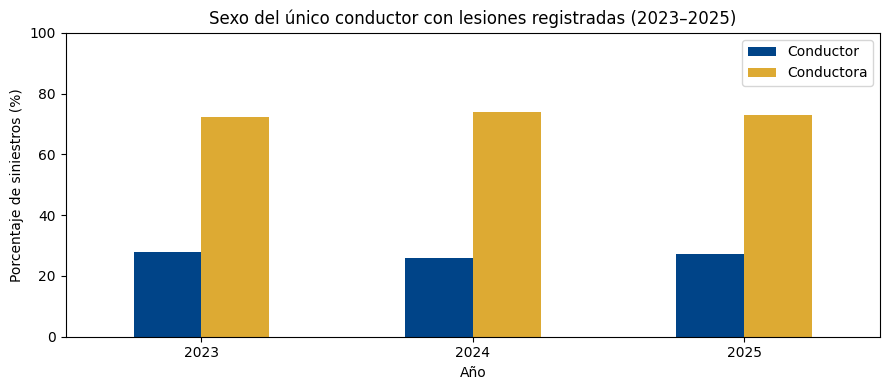

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))

porcentajes_por_año_un_lesionado.set_index("Año").astype(float).plot.bar(
    ax=ax,
    color=["#004488", "#DDAA33"],
    rot=0
)

ax.set(
    title="Sexo del único conductor con lesiones registradas (2023–2025)",
    xlabel="Año",
    ylabel="Porcentaje de siniestros (%)"
)

ax.set_ylim(0, 100)

ax.legend(["Conductor", "Conductora"])

fig.tight_layout()
plt.show()

#### 4.1.2. Interpretación de las figuras obtenidas ####

Cuando solo uno de los conductores tiene lesiones registradas, se trata de la conductora en poco más del 72% de los casos, durante los tres años de interés. Más específicamente:

- En 2023, la conductora fue la única con lesiones registradas en el 72.17% de los casos.

- En 2024, la conductora fue la única con lesiones registradas en el 74.04% de los casos

- En 2025, la conductora fue la única con lesiones registradas en el 72.86% de los casos

*Limitaciones.* Este hallazgo refleja una asociación descriptiva dentro de los registros policiales, no causalidad por sexo biológico. STATS19 advierte subregistro de lesiones no mortales y no incluye variables críticas como la masa/tamaño de cada automóvil (ej. auto compacto vs. SUV), la velocidad exacta de impacto o el uso/ajuste del cinturón de seguridad.


### 4.2. Siniestros entre dos automóviles con ambos conductores lesionados ###


Pregunta conductora:

> Si ambos conductores presentan lesiones registradas de distinta gravedad, ¿hay una tendencia sobre quién presenta las más graves?

#### 4.2.1. Obtención de frecuencias relativas y absolutas ####

In [ ]:
resumen = []

for año in análisis:

    vehículos = análisis[año]["vehicles"]

    def más_grave(collision_index: str) -> int:

        '''
        Devuelve:

        1 si el hombre tiene lesiones más graves,

        2 si la mujer tiene lesiones más grave y

        0 si ambos tienen la misma gravedad.
        '''

        # Extraemos la pareja correspondiente con el identificador de siniestro
        # En este caso, `pareja` es un DataFrame con dos filas

        pareja = vehículos[vehículos["collision_index"] == collision_index]

        # Separamos los registros del conductor y de la conductora

        hombre = pareja[pareja["sex_of_driver"] == 1]
        mujer = pareja[pareja["sex_of_driver"] == 2]

        # Obtenemos las gravedades

        gravedad_hombre = hombre["casualty_severity"].iloc[0]
        gravedad_mujer = mujer["casualty_severity"].iloc[0]

        # ¡Ojo! La variable `casualty_severity` va de 1 a 3, donde 1 denota lesiones mortales, 2 denota lesiones graves y 3 denota lesiones leves

        # Es decir, números más bajos significan mayor gravedad

        if gravedad_hombre < gravedad_mujer:
            return 1

        elif gravedad_mujer < gravedad_hombre:
            return 2

        else:
            return 0

    # Seleccionamos los siniestros con ambos conductores lesionados.

    conductores_lesionados_por_siniestro = vehículos.groupby("collision_index")["casualty_severity"].count()

    siniestros_con_ambos_lesionados = conductores_lesionados_por_siniestro[
        conductores_lesionados_por_siniestro == 2
        ].index

    # Aplicamos la función a cada siniestro.

    resultados = pd.Series([más_grave(i) for i in siniestros_con_ambos_lesionados])

    # Contamos los resultados de las comparaciones.

    hombre = (resultados == 1).sum()
    mujer = (resultados == 2).sum()
    igual = (resultados == 0).sum()

    resumen.append({
        "Año": año,
        "Siniestros seleccionados (n)": len(análisis[año]["collisions"]),
        "Ambos lesionados (n)": len(siniestros_con_ambos_lesionados),
        "Distinta gravedad (n)": hombre + mujer,
        "Hombre más grave (n)": hombre,
        "Mujer más grave (n)": mujer,
        "Igual gravedad (n)": igual
    })

tabla_resumen = pd.DataFrame(resumen)



La tabla con el resumen de datos es la siguiente:

In [ ]:
display(tabla_resumen)

,Año,Siniestros seleccionados (n),Ambos lesionados (n),Distinta gravedad (n),Hombre más grave (n),Mujer más grave (n),Igual gravedad (n)
0,2023,2202,742,205,80,125,537
1,2024,2197,771,232,93,139,539
2,2025,2078,703,214,89,125,489


#### 4.2.2. Visualización ####

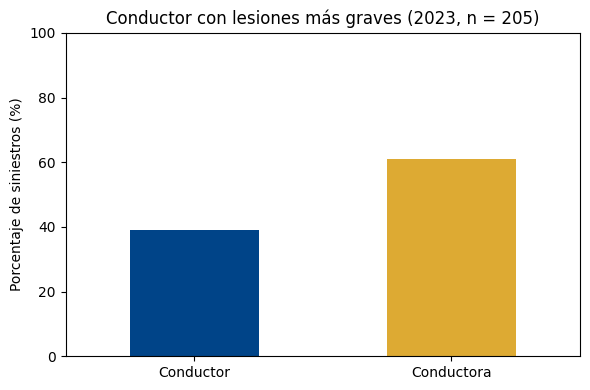

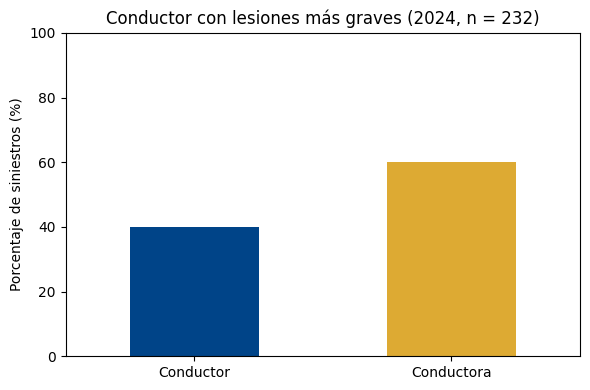

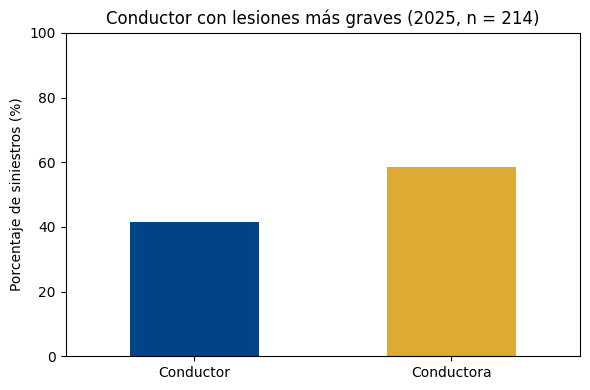

In [ ]:
def graficar_gravedad(año):

    datos = tabla_resumen[tabla_resumen["Año"] == año].iloc[0]

    n = datos["Distinta gravedad (n)"]

    porcentajes = pd.Series({
        "Conductor": 100 * datos["Hombre más grave (n)"] / n,
        "Conductora": 100 * datos["Mujer más grave (n)"] / n
    })

    fig, ax = plt.subplots(figsize=(6, 4))

    porcentajes.plot.bar(
        ax=ax,
        color=["#004488", "#DDAA33"],
        rot=0
    )

    ax.set(
        title=f"Conductor con lesiones más graves ({año}, n = {n})",
        xlabel="",
        ylabel="Porcentaje de siniestros (%)"
    )

    ax.set_ylim(0, 100)

    fig.tight_layout()
    plt.show()


graficar_gravedad(2023)
graficar_gravedad(2024)
graficar_gravedad(2025)

#### 4.2.3. Interpretación de la figura ####

Cuando ambos conductores tienen lesiones registradas con distinto nivel de gravedad, las conductoras concentran alrededor del 60% de los casos de mayor gravedad. Más específicamente:

- En 2023, entre todos los siniestros donde ambos tuvieron lesiones registradas de distinta gravedad, la mujer tenía las lesiones registradas más graves en el 60.98% de los casos.

- En 2024, entre todos los siniestros donde ambos tuvieron lesiones registradas de distinta gravedad, la mujer tenía las lesiones registradas más graves en el 59.91% de los casos.

- En 2025, entre todos los siniestros donde ambos tuvieron lesiones registradas de distinta gravedad, la mujer tenía las lesiones registradas más graves en el 58.41% de los casos.

Los resultados son consistentes con las observaciones de la pregunta 1. A su vez, estos datos mantienen una estabilidad anual.

*Limitaciones.* El tamaño de muestra anual es considerablemente menor que en el caso anterior pues se observó que para la mayoría de siniestros con ambos conductores lesionados, persisten los empates (ambos conductores con la misma gravedad de lesiones). Además, insistimos en que para esta pregunta persisten factores no medidos en STATS19 como la masa relativa de cada automóvil y la velocidad de cada automóvil el recibir un primer impacto, entre otros.

## 5. Conclusiones ##

### 5.1. Principales hallazgos frente a las preguntas de investigación

A partir del análisis descriptivo de los registros oficiales de STATS19 (2023–2025), enfocado en siniestros de exactamente dos vehículos, ambos automóviles, con conductores de distinto sexo y ambos puntos de primer impacto frontales, se obtuvieron dos resultados consistentes:

1. **Respecto a la primera pregunta conductora.**

   Cuando solo uno de los dos conductores registra lesiones, *más del 72% de los casos corresponden a la conductora* en los tres años analizados (72.17% en 2023, 74.04% en 2024 y 72.86% en 2025), frente a un porcentaje en conductores hombres de entre el 26% y el 28%.

2. **Respecto a la segunda pregunta conductora.**

   Cuando ambos conductores tienen lesiones registradas pero con distinta severidad, *alrededor del 60% de los casos de mayor gravedad corresponden a la conductora* (60.98% en 2023, 59.91% en 2024 y 58.41% en 2025).

### 5.2. Alcances y limitaciones.

#### 5.2.1. Lo que *sí* permiten concluir ####

  Consideramos que, a grandes rasgos, nuestro análisis permite concluir que:

  > Dentro de los siniestros de exactamente dos automóviles registrados por la policía en Gran Bretaña entre 2023 y 2025 y para los cuales los conductores fueron de distintos sexos y ambos automóviles registraron el frente como un primer punto de impacto, existe diferencia marcada y relativamente estable en el tiempo entre hombres y mujeres en cuanto a quién figura como:
  >
  >- El único conductor con lesiones registradas (en el caso de los siniestros donde solo se registró un conductor lesionado), o bien, como
  >
  >- El conductor cuyas lesiones registradas fueron más graves (en el caso de los siniestros donde ambos conductores tuvieron lesiones registradas, de distinta severidad según lo reportado por las fuerzas policiales).

  Más aún, se observó que es la conductora quien figuró con mayor frecuencia en las categoría de único conductor lesionado, para la primera pregunta, y conductor lesionado con las lesiones más graves, para la segunda pregunta.

#### 5.2.2. Lo que *no* permiten concluir ####

Nuestro análisis es exploratorio y **no pretende demostrar una relación causal** entre ninguna de las variables observadas.

En particular, nuestro análisis no permite establecer, por ejemplo, una relación causal  entre el sexo de un conductor y la propensión de tener lesiones registradas (de mayor o menor gravedad) en un siniestro de dos automóviles.

De entrada, es importante recordar que en STATS19 solo se registran siniestros viales que:

1. Llegaron a conocimiento de las fuerzas policiales

2. Dejaron algún tipo de víctima.

3. Sucedieron en la vía pública.

De esta manera, los datos registrados en STATS19 **no son una muestra fiel de todos los ocurridos en Gran Bretaña.**

---

Otra dimensión a considerar es que, incluso en el universo de siniestros contemplados por STATS19, las tablas no recopilan todas las variables posibles que podrían explicar, total o parcialmente, la diferencia observada en nuestros resultados.

Por ejemplo, STATS19 no recopila datos sobre la masa de los vehículos. Esto es relevante pues, por ejemplo, la categoría `vehicle_type == 9` agrupa automóviles de tipos muy variados (desde subcompactos hasta camionetas SUV).

Lo anterior es particularmente importante para nuestras preguntas centrales, pues si existe una diferencia sistemática en el tamaño o masa promedio de los automóviles conducidos por mujeres y hombres, esto podría influir los datos que analizamos en la sección 4 de este proyecto.

# Sección nueva
### 5.3. Líneas futuras de análisis

En módulos posteriores del diplomado, este trabajo puede extenderse mediante pruebas de hipótesis formales para proporciones emparejadas (como la prueba de McNemar), modelos de regresión logística condicional por siniestro y el cruce con bases vehiculares externas que incorporen la masa y clasificación de seguridad de cada unidad.

## 6. Anexo: Análisis exploratorio complementario por pares ##

En las secciones 4 y 5 respondimos nuestras dos preguntas conductoras principales. Como complemento exploratorio —manteniendo estrictamente la **estructura emparejada** de nuestra población de estudio (siniestros de exactamente dos automóviles, pareja hombre–mujer y primer punto de impacto frontal en ambos vehículos)—, en este anexo incorporamos una variable numérica adicional disponible en `vehicles`: la **cilindrada del motor (`engine_capacity_cc`)**.

### 6.1. Duelo de motores: cilindrada del automóvil dentro de cada pareja ###

En la sección 5.2.2 advertimos que STATS19 no registra la masa de los vehículos y que la categoría `vehicle_type == 9` agrupa desde autos subcompactos hasta camionetas SUV. Aunque la cilindrada del motor (medida en centímetros cúbicos, $\text{cm}^3$ o `cc`) no equivale exactamente al peso del automóvil, suele asociarse con el tamaño y segmento de la unidad.

A partir de esto, formulamos la siguiente pregunta exploratoria complementaria:

> Dentro de nuestra población emparejada de choques frontales, ¿cómo se comportan la cilindrada del motor y la **diferencia de cilindrada dentro de cada pareja** ($\Delta\text{cc} = \text{cc}_{\text{hombre}} - \text{cc}_{\text{mujer}}$) según qué conductor presenta lesiones registradas?

#### 6.1.1. Verificación y auditoría de calidad de `engine_capacity_cc` ####

Antes de calcular medidas de tendencia central o dispersión, verificamos que `engine_capacity_cc` esté presente en los tres años, la incorporamos a una copia independiente de nuestra población de estudio (sin modificar `datos` ni `análisis`) y auditamos posibles problemas de calidad: valores nulos estándar (`NaN`), código `-1` (dato faltante o no vinculado), valores en `0` cc (que pueden corresponder a vehículos eléctricos o errores de captura) y posibles valores atípicos extremos (`< 500` cc o `> 8000` cc para un automóvil).

In [ ]:
# Verificamos que la variable `engine_capacity_cc` exista en las tablas originales de los tres años

for año in datos:
    assert "engine_capacity_cc" in datos[año]["vehicles"].columns, (
        f"Falta la columna engine_capacity_cc en vehicles ({año})."
    )

# Creamos una copia independiente de los vehículos de nuestra población de estudio
# e incorporamos `engine_capacity_cc` desde las tablas originales sin alterar `datos` ni `análisis`

anexo_vehículos = {}
auditoría_cc = []

for año in análisis:

    # Recuperamos la cilindrada desde la tabla original de vehículos

    cc_original = datos[año]["vehicles"][
        ["collision_index", "vehicle_reference", "engine_capacity_cc"]
    ].copy()

    # Unimos con nuestra población emparejada validando relación uno a uno

    vehículos_cc = análisis[año]["vehicles"].merge(
        cc_original,
        on=["collision_index", "vehicle_reference"],
        how="left",
        validate="one_to_one"
    )

    anexo_vehículos[año] = vehículos_cc

    # Auditamos nulos, códigos especiales (-1 y 0) y posibles valores atípicos

    cc = vehículos_cc["engine_capacity_cc"]
    n_total = len(cc)
    n_nan = int(cc.isna().sum())
    n_menos_uno = int((cc == -1).sum())
    n_cero = int((cc == 0).sum())
    n_bajo = int(((cc > 0) & (cc < 500)).sum())
    n_alto = int((cc > 8000).sum())

    # Comparamos la media antes (con códigos -1) y después de excluir valores no positivos

    cc_positivos = cc.where(cc > 0, np.nan)
    media_antes = round(cc.mean(), 2)
    media_después = round(cc_positivos.mean(), 2) if cc_positivos.notna().any() else np.nan
    desv_después = round(cc_positivos.std(), 2) if cc_positivos.notna().any() else np.nan

    auditoría_cc.append({
        "Año": año,
        "Vehículos (n)": n_total,
        "NaN estándar": n_nan,
        "Código -1 (n)": n_menos_uno,
        "Código -1 (%)": round(100 * n_menos_uno / n_total, 2),
        "Valor 0 cc (n)": n_cero,
        "Atípicos <500 cc": n_bajo,
        "Atípicos >8000 cc": n_alto,
        "Media ANTES (con -1)": media_antes,
        "Media DESPUÉS (>0)": media_después,
        "Desv. Est. (>0)": desv_después
    })

tabla_auditoría_cc = pd.DataFrame(auditoría_cc)
tabla_auditoría_cc.to_csv("resultados/anexo_auditoria_cilindrada.csv", index=False)
display(tabla_auditoría_cc)

,Año,Vehículos (n),NaN estándar,Código -1 (n),Código -1 (%),Valor 0 cc (n),Atípicos <500 cc,Atípicos >8000 cc,Media ANTES (con -1),Media DESPUÉS (>0),Desv. Est. (>0)
0,2023,4404,0,377,8.56,0,1,0,1479.53,1618.14,514.12
1,2024,4394,0,659,15.00,0,2,0,1337.12,1573.21,469.43
2,2025,4156,0,388,9.34,0,0,0,1445.64,1594.60,488.58


#### 6.1.2. Decisión de limpieza y transformación emparejada ####

- **Problema.** En `engine_capacity_cc`, los datos faltantes no aparecen como `NaN`, sino codificados con `-1` (lo cual sesga severamente hacia abajo cualquier promedio y distorsiona la desviación estándar). Asimismo, pueden presentarse valores en `0` cc (como vehículos eléctricos sin cilindrada de combustión o registros incompletos) y valores extremos fuera del rango plausible para un automóvil de pasajeros. Además, para respetar la estructura por pares de nuestro estudio, no conviene promediar hombres y mujeres en dos bolsas separadas, sino comparar ambos automóviles *dentro del mismo siniestro*.

- **Cómo lo abordamos (criterio estadístico).**
  1. **Recodificación sin imputación:** Reemplazamos por `np.nan` los códigos `-1`, los valores `0` cc y los registros físicamente inverosímiles para un automóvil (`< 500` cc o `> 8000` cc), conservando los motores grandes legítimos (por ejemplo, camionetas o autos deportivos de 3,000 a 6,000+ cc). Decidimos **no imputar** los faltantes porque asignar una cilindrada promedio artificial distorsionaría la diferencia real dentro de cada pareja.
  2. **Transformación a tabla por pares (1 fila = 1 siniestro):** Reorganizamos los datos para que cada fila represente un siniestro completo con las columnas `cc_hombre`, `cc_mujer`, el desenlace de lesiones y la **diferencia emparejada** $\Delta\text{cc} = \text{cc}_{\text{hombre}} - \text{cc}_{\text{mujer}}$ (valores positivos indican que el hombre conducía un motor más grande; valores negativos, que la mujer conducía un motor más grande).

- **Consecuencias para nuestros datos y resultados.** Únicamente los siniestros donde **ambos** automóviles cuentan con cilindrada válida entran en el cálculo de $\Delta\text{cc}$ (sin afectar los conteos de las secciones 4.1 y 4.2). A continuación documentamos cuántos pares válidos se conservan por año, calculamos las medidas de tendencia central, dispersión (desviación estándar) y posición ($Q_1$, mediana, $Q_3$ e $IQR$), y estratificamos los choques de un solo lesionado según quién conducía el motor de mayor cilindrada.

In [ ]:
pares_lista = []
disponibilidad_pares = []

for año, vehículos_cc in anexo_vehículos.items():

    df = vehículos_cc.copy()

    # Recodificamos códigos no válidos (-1 y 0) y valores inverosímiles (<500 o >8000 cc) como NaN

    df["cc_limpia"] = df["engine_capacity_cc"].where(
        (df["engine_capacity_cc"] >= 500) & (df["engine_capacity_cc"] <= 8000),
        np.nan
    )

    # Separamos los registros del conductor (hombre) y de la conductora (mujer)

    hombres = df[df["sex_of_driver"] == 1][
        ["collision_index", "cc_limpia", "lesión_registrada", "casualty_severity"]
    ].rename(columns={
        "cc_limpia": "cc_hombre",
        "lesión_registrada": "lesión_hombre",
        "casualty_severity": "gravedad_hombre"
    })

    mujeres = df[df["sex_of_driver"] == 2][
        ["collision_index", "cc_limpia", "lesión_registrada", "casualty_severity"]
    ].rename(columns={
        "cc_limpia": "cc_mujer",
        "lesión_registrada": "lesión_mujer",
        "casualty_severity": "gravedad_mujer"
    })

    # Unimos ambos conductores del mismo siniestro en una sola fila (1 fila = 1 par)

    pares = hombres.merge(
        mujeres,
        on="collision_index",
        how="inner",
        validate="one_to_one"
    )
    pares["Año"] = año

    # Clasificamos el desenlace de lesiones de cada siniestro emparejado

    condiciones = [
        (pares["lesión_hombre"]) & (~pares["lesión_mujer"]),
        (~pares["lesión_hombre"]) & (pares["lesión_mujer"]),
        (pares["lesión_hombre"]) & (pares["lesión_mujer"])
    ]
    etiquetas = [
        "Solo hombre lesionado",
        "Solo mujer lesionada",
        "Ambos lesionados"
    ]
    pares["desenlace"] = np.select(
        condiciones,
        etiquetas,
        default="Ningún conductor lesionado"
    )

    # Calculamos la diferencia de cilindrada dentro de cada pareja (hombre menos mujer)

    pares["dif_cc"] = pares["cc_hombre"] - pares["cc_mujer"]

    # Registramos la disponibilidad anual de pares con ambas cilindradas válidas

    n_pares = len(pares)
    n_válidos = int(pares["dif_cc"].notna().sum())

    disponibilidad_pares.append({
        "Año": año,
        "Siniestros emparejados (n)": n_pares,
        "Pares con ambas cilindradas válidas (n)": n_válidos,
        "% disponible": round(100 * n_válidos / n_pares, 2)
    })

    pares_lista.append(pares)

# Consolidamos todos los pares del periodo y conservamos los que tienen ambas cilindradas válidas

pares_cc_todos = pd.concat(pares_lista, ignore_index=True)
pares_cc_válidos = pares_cc_todos[pares_cc_todos["dif_cc"].notna()].copy()

# Detectamos automáticamente qué años aportaron pares válidos para etiquetar tablas y gráficas

años_con_datos = sorted(pares_cc_válidos["Año"].unique().tolist())
etiqueta_años = (
    f"{años_con_datos[0]}–{años_con_datos[-1]}"
    if len(años_con_datos) > 1
    else f"{años_con_datos[0]}"
)

print("1) Disponibilidad de pares con cilindrada válida en ambos automóviles:")
tabla_disponibilidad = pd.DataFrame(disponibilidad_pares)
display(tabla_disponibilidad)

# Función auxiliar para calcular medidas de tendencia central, dispersión y posición

def resumir_variable(serie, nombre):
    return {
        "Grupo / Variable": nombre,
        "Pares (n)": int(serie.count()),
        "Media (cc)": round(serie.mean(), 2),
        "Desv. Estándar (cc)": round(serie.std(), 2),
        "Mediana (cc)": round(serie.median(), 2),
        "Q1 (cc)": round(serie.quantile(0.25), 2),
        "Q3 (cc)": round(serie.quantile(0.75), 2),
        "IQR (cc)": round(serie.quantile(0.75) - serie.quantile(0.25), 2),
    }

# Calculamos los estadísticos generales y los de la diferencia emparejada Δcc por desenlace

filas_estadísticos = [
    resumir_variable(pares_cc_válidos["cc_hombre"], "Cilindrada auto del hombre (global)"),
    resumir_variable(pares_cc_válidos["cc_mujer"], "Cilindrada auto de la mujer (global)"),
    resumir_variable(pares_cc_válidos["dif_cc"], "Diferencia Δcc = hombre − mujer (global)"),
]

for grupo in ["Solo hombre lesionado", "Solo mujer lesionada", "Ambos lesionados"]:
    sub = pares_cc_válidos.loc[pares_cc_válidos["desenlace"] == grupo, "dif_cc"]
    if len(sub) > 0:
        filas_estadísticos.append(resumir_variable(sub, f"Δcc | {grupo}"))

tabla_estadísticos_cc = pd.DataFrame(filas_estadísticos)
tabla_estadísticos_cc.to_csv("resultados/anexo_estadisticos_cilindrada.csv", index=False)

print(f"\n2) Medidas de tendencia central, dispersión y posición ({etiqueta_años}):")
display(tabla_estadísticos_cc)

# En siniestros con exactamente un conductor lesionado, clasificamos quién tenía mayor cilindrada

pares_uno = pares_cc_válidos[
    pares_cc_válidos["desenlace"].isin(["Solo hombre lesionado", "Solo mujer lesionada"])
].copy()

cond_ventaja = [
    pares_uno["dif_cc"] > 100,
    pares_uno["dif_cc"].abs() <= 100,
    pares_uno["dif_cc"] < -100
]
etiq_ventaja = [
    "Motor del hombre > mujer (>100 cc)",
    "Motores similares (|Δcc| ≤ 100 cc)",
    "Motor de la mujer > hombre (>100 cc)"
]
pares_uno["ventaja_motor"] = np.select(cond_ventaja, etiq_ventaja, default="Otro")

filas_ventaja = []
for cat in etiq_ventaja:
    sub = pares_uno[pares_uno["ventaja_motor"] == cat]
    n_cat = len(sub)
    n_hom = int((sub["desenlace"] == "Solo hombre lesionado").sum())
    n_muj = int((sub["desenlace"] == "Solo mujer lesionada").sum())
    if n_cat > 0:
        filas_ventaja.append({
            "Comparación de motores dentro del par": cat,
            "Siniestros (n)": n_cat,
            "Solo hombre (n)": n_hom,
            "Solo mujer (n)": n_muj,
            "Solo hombre (%)": round(100 * n_hom / n_cat, 2),
            "Solo mujer (%)": round(100 * n_muj / n_cat, 2),
        })

tabla_ventaja_motor = pd.DataFrame(filas_ventaja)
tabla_ventaja_motor.to_csv("resultados/anexo_lesion_por_ventaja_motor.csv", index=False)

print(f"\n3) Porcentaje de lesión única según ventaja de cilindrada dentro del par ({etiqueta_años}):")
display(tabla_ventaja_motor)

1) Disponibilidad de pares con cilindrada válida en ambos automóviles:


,Año,Siniestros emparejados (n),Pares con ambas cilindradas válidas (n),% disponible
0,2023,2202,1852,84.11
1,2024,2197,1627,74.06
2,2025,2078,1714,82.48



2) Medidas de tendencia central, dispersión y posición (2023–2025):


,Grupo / Variable,Pares (n),Media (cc),Desv. Estándar (cc),Mediana (cc),Q1 (cc),Q3 (cc),IQR (cc)
0,Cilindrada auto del hombre (global),5193,1692.03,540.13,1597.0,1360.0,1984.0,624.0
1,Cilindrada auto de la mujer (global),5193,1507.98,431.16,1461.0,1200.0,1600.0,400.0
2,Diferencia Δcc = hombre − mujer (global),5193,184.05,687.13,165.0,-202.0,571.0,773.0
3,Δcc | Solo hombre lesionado,791,1.79,702.02,0.0,-396.0,444.0,840.0
4,Δcc | Solo mujer lesionada,2119,292.04,676.23,236.0,-99.0,609.0,708.0
5,Δcc | Ambos lesionados,1805,145.62,673.50,100.0,-243.0,508.0,751.0



3) Porcentaje de lesión única según ventaja de cilindrada dentro del par (2023–2025):


,Comparación de motores dentro del par,Siniestros (n),Solo hombre (n),Solo mujer (n),Solo hombre (%),Solo mujer (%)
0,Motor del hombre > mujer (>100 cc),1615,334,1281,20.68,79.32
1,Motores similares (|Δcc| ≤ 100 cc),448,129,319,28.79,71.21
2,Motor de la mujer > hombre (>100 cc),847,328,519,38.72,61.28


#### 6.1.3. Visualizaciones del análisis emparejado de cilindrada ####

Para interpretar visualmente los resultados anteriores construimos dos figuras:

1. **Gráfico de dispersión ("Duelo de motores"):** Cada punto representa un siniestro con un solo conductor lesionado, ubicando en el eje horizontal la cilindrada del automóvil del hombre y en el vertical la de la mujer. La diagonal punteada señala igualdad de cilindrada.
2. **Panel comparativo:** A la izquierda, un **diagrama de violín con diagrama de caja superpuesto** que muestra la distribución completa, cuartiles y media de la diferencia emparejada $\Delta\text{cc}$ según el desenlace; a la derecha, un **gráfico de barras agrupadas** con el porcentaje de lesiones únicas según cuál automóvil tenía mayor cilindrada.

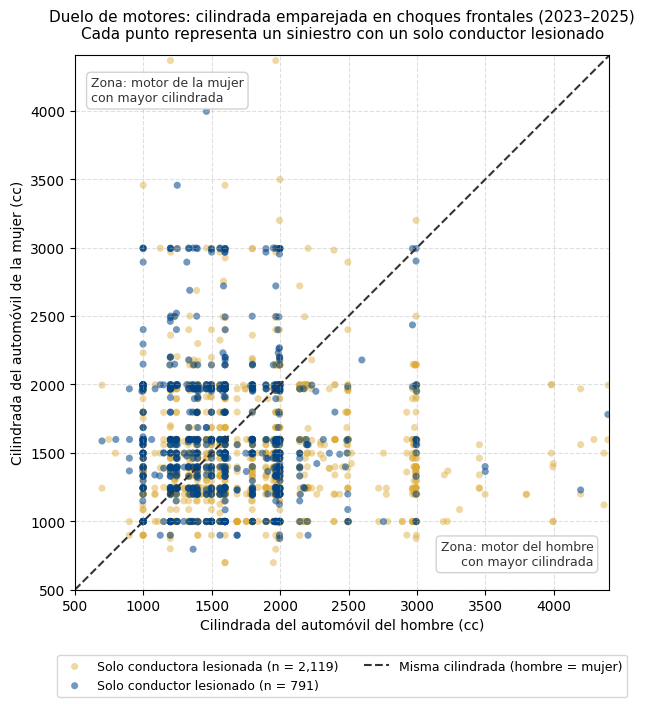

In [ ]:
# Separamos los pares con un solo conductor lesionado según el sexo de la víctima

solo_hombre = pares_uno[pares_uno["desenlace"] == "Solo hombre lesionado"]
solo_mujer = pares_uno[pares_uno["desenlace"] == "Solo mujer lesionada"]

# Ajustamos el límite superior visual al percentil 99.5 (con tope en 5,000 cc)
# para evitar que unos pocos autos deportivos extremos aplasten la nube principal

limite_sup = min(
    max(pares_uno["cc_hombre"].quantile(0.995), pares_uno["cc_mujer"].quantile(0.995)) * 1.05,
    5000
)
limite_inf = 500

fig, ax = plt.subplots(figsize=(7.5, 7.2))

# Graficamos ambos grupos respetando la paleta de color de la sección 4 (#004488 y #DDAA33)

ax.scatter(
    solo_mujer["cc_hombre"],
    solo_mujer["cc_mujer"],
    color="#DDAA33",
    alpha=0.45,
    s=26,
    edgecolors="none",
    label=f"Solo conductora lesionada (n = {len(solo_mujer):,})"
)

ax.scatter(
    solo_hombre["cc_hombre"],
    solo_hombre["cc_mujer"],
    color="#004488",
    alpha=0.55,
    s=26,
    edgecolors="none",
    label=f"Solo conductor lesionado (n = {len(solo_hombre):,})"
)

# Dibujamos la línea diagonal de referencia (misma cilindrada en ambos autos)

ax.plot(
    [limite_inf, limite_sup],
    [limite_inf, limite_sup],
    color="#333333",
    linestyle="--",
    linewidth=1.5,
    label="Misma cilindrada (hombre = mujer)"
)

# Agregamos recuadros guía para facilitar la lectura de cada zona

ax.text(
    limite_sup - (limite_sup - limite_inf) * 0.03,
    limite_inf + (limite_sup - limite_inf) * 0.04,
    "Zona: motor del hombre\ncon mayor cilindrada",
    ha="right",
    va="bottom",
    fontsize=9,
    color="#333333",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.88, edgecolor="#CCCCCC")
)

ax.text(
    limite_inf + (limite_sup - limite_inf) * 0.03,
    limite_sup - (limite_sup - limite_inf) * 0.04,
    "Zona: motor de la mujer\ncon mayor cilindrada",
    ha="left",
    va="top",
    fontsize=9,
    color="#333333",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.88, edgecolor="#CCCCCC")
)

ax.set_xlim(limite_inf, limite_sup)
ax.set_ylim(limite_inf, limite_sup)
ax.set_aspect("equal", adjustable="box")

ax.set_title(
    f"Duelo de motores: cilindrada emparejada en choques frontales ({etiqueta_años})\n"
    "Cada punto representa un siniestro con un solo conductor lesionado",
    fontsize=11,
    pad=12
)
ax.set_xlabel("Cilindrada del automóvil del hombre (cc)")
ax.set_ylabel("Cilindrada del automóvil de la mujer (cc)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2, frameon=True, fontsize=9)
ax.grid(True, linestyle="--", alpha=0.4)

fig.tight_layout()
plt.savefig("resultados/anexo_fig1_duelo_motores.png", dpi=300, bbox_inches="tight")
plt.show()

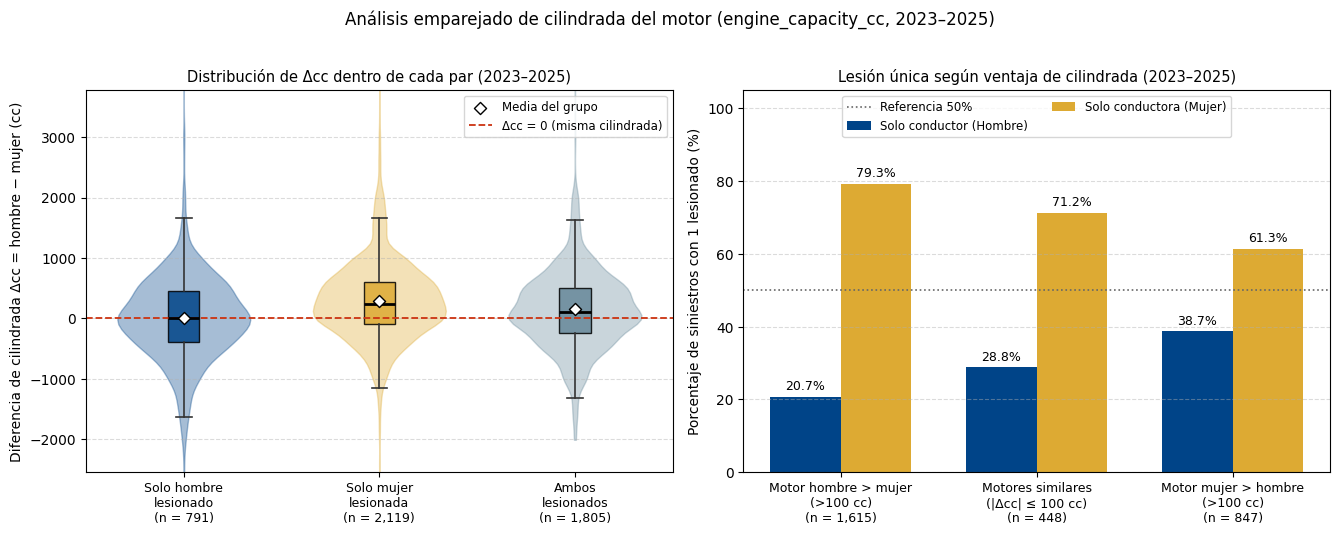

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

# --- Panel izquierdo: Diagrama de violín + boxplot de la diferencia emparejada Δcc ---

grupos_orden = [
    ("Solo hombre lesionado", "Solo hombre\nlesionado", "#004488"),
    ("Solo mujer lesionada", "Solo mujer\nlesionada", "#DDAA33"),
    ("Ambos lesionados", "Ambos\nlesionados", "#668899"),
]

datos_violín = []
etiquetas_violín = []
colores_violín = []

for clave, etiq, col in grupos_orden:
    serie = pares_cc_válidos.loc[pares_cc_válidos["desenlace"] == clave, "dif_cc"].dropna()
    if len(serie) > 0:
        datos_violín.append(serie.values)
        etiquetas_violín.append(f"{etiq}\n(n = {len(serie):,})")
        colores_violín.append(col)

posiciones = np.arange(1, len(datos_violín) + 1)

# Graficamos los violines para visualizar la densidad completa de Δcc

vp = axes[0].violinplot(
    datos_violín,
    positions=posiciones,
    widths=0.68,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

for cuerpo, color in zip(vp["bodies"], colores_violín):
    cuerpo.set_facecolor(color)
    cuerpo.set_edgecolor(color)
    cuerpo.set_alpha(0.35)

# Superponemos un boxplot estilizado para destacar Q1, mediana y Q3

bp = axes[0].boxplot(
    datos_violín,
    positions=posiciones,
    widths=0.16,
    patch_artist=True,
    showfliers=False,
    medianprops=dict(color="black", linewidth=2.0),
    whiskerprops=dict(color="#333333", linewidth=1.2),
    capprops=dict(color="#333333", linewidth=1.2)
)

for caja, color in zip(bp["boxes"], colores_violín):
    caja.set_facecolor(color)
    caja.set_alpha(0.85)

# Señalamos la media de cada grupo con un rombo blanco

medias = [np.mean(d) for d in datos_violín]
axes[0].scatter(
    posiciones,
    medias,
    marker="D",
    color="white",
    edgecolor="black",
    s=38,
    zorder=5,
    label="Media del grupo"
)

# Línea de referencia en 0 (misma cilindrada en ambos autos)

axes[0].axhline(0, color="#CC3311", linestyle="--", linewidth=1.3, label="Δcc = 0 (misma cilindrada)")

# Ajustamos el eje vertical al rango central (0.5% a 99.5%) para evitar aplastamiento por extremos

y_inf, y_sup = pares_cc_válidos["dif_cc"].quantile([0.005, 0.995])
margen_y = (y_sup - y_inf) * 0.18
axes[0].set_ylim(y_inf - margen_y, y_sup + margen_y * 1.35)

axes[0].set_xticks(posiciones)
axes[0].set_xticklabels(etiquetas_violín, fontsize=9)
axes[0].set_ylabel("Diferencia de cilindrada Δcc = hombre − mujer (cc)")
axes[0].set_title(f"Distribución de Δcc dentro de cada par ({etiqueta_años})", fontsize=10.5)
axes[0].legend(loc="upper right", frameon=True, fontsize=8.5)
axes[0].grid(axis="y", linestyle="--", alpha=0.45)

# --- Panel derecho: % de lesión única según ventaja de cilindrada dentro del par ---

etiquetas_cortas = [
    f"Motor hombre > mujer\n(>100 cc)\n(n = {int(row['Siniestros (n)']):,})"
    if "hombre >" in row["Comparación de motores dentro del par"]
    else (
        f"Motores similares\n(|Δcc| ≤ 100 cc)\n(n = {int(row['Siniestros (n)']):,})"
        if "similares" in row["Comparación de motores dentro del par"]
        else f"Motor mujer > hombre\n(>100 cc)\n(n = {int(row['Siniestros (n)']):,})"
    )
    for _, row in tabla_ventaja_motor.iterrows()
]

x_bar = np.arange(len(tabla_ventaja_motor))
ancho = 0.36

b1 = axes[1].bar(
    x_bar - ancho / 2,
    tabla_ventaja_motor["Solo hombre (%)"],
    width=ancho,
    color="#004488",
    label="Solo conductor (Hombre)"
)
b2 = axes[1].bar(
    x_bar + ancho / 2,
    tabla_ventaja_motor["Solo mujer (%)"],
    width=ancho,
    color="#DDAA33",
    label="Solo conductora (Mujer)"
)

axes[1].axhline(50, color="#666666", linestyle=":", linewidth=1.2, label="Referencia 50%")
axes[1].set_xticks(x_bar)
axes[1].set_xticklabels(etiquetas_cortas, fontsize=9)
axes[1].set_ylim(0, 105)
axes[1].set_ylabel("Porcentaje de siniestros con 1 lesionado (%)")
axes[1].set_title(f"Lesión única según ventaja de cilindrada ({etiqueta_años})", fontsize=10.5)
axes[1].legend(loc="upper center", ncol=2, frameon=True, fontsize=8.5)
axes[1].grid(axis="y", linestyle="--", alpha=0.45)

axes[1].bar_label(b1, fmt="%.1f%%", padding=3, fontsize=9)
axes[1].bar_label(b2, fmt="%.1f%%", padding=3, fontsize=9)

fig.suptitle(
    f"Análisis emparejado de cilindrada del motor (engine_capacity_cc, {etiqueta_años})",
    fontsize=12,
    y=1.02
)
fig.tight_layout()
plt.savefig("resultados/anexo_fig2_diferencia_cilindrada.png", dpi=300, bbox_inches="tight")
plt.show()

#### 6.1.4. Interpretación y alcances del análisis de cilindrada ####

* **Qué muestran los datos y las figuras:**
  * **Calidad y muestra:** Recodificar el código `-1` (entre 8.6% y 15.0% de los vehículos por año) eliminó un sesgo hacia abajo de hasta 236 cc en la media anual. En total se analizaron **5,193 pares** con cilindrada válida en ambos autos (80.18% de la población emparejada de 2023–2025).
  * **Diferencia dentro de cada par ($\Delta\text{cc} = \text{cc}_{\text{hombre}} - \text{cc}_{\text{mujer}}$):** Globalmente los hombres conducen motores de mayor cilindrada (media de 1,692 vs. 1,508 cc; $\Delta\text{cc}$ promedio de +184.05 cc y desviación estándar de 687.13 cc). Cuando **solo se lesiona el hombre** ($n = 791$), la diferencia está centrada en cero (media +1.79 cc, mediana **0.0 cc**, DE 702.02 cc); en cambio, cuando **solo se lesiona la conductora** ($n = 2,119$), sube a una media de +292.04 cc y mediana de **+236.0 cc** (DE 676.23 cc).
  * **Efecto por ventaja de motor:** El porcentaje de lesiones únicas en conductoras cae **18 puntos porcentuales** según quién trae el motor más grande: **79.32%** cuando el motor del hombre es mayor ($n = 1,615$), **71.21%** en motores similares ($n = 448$) y **61.28%** cuando el motor de la mujer es mayor ($n = 847$).

* **Por qué es relevante:** Confirma empíricamente que el tamaño aproximado del automóvil dentro de cada pareja se asocia con una parte importante de la brecha, pero **no la explica por completo**: incluso con motores equivalentes o más grandes, las conductoras siguen concentrando la mayoría de las lesiones únicas.

* **Limitaciones:** La cilindrada es solo una aproximación indirecta a la masa real del vehículo (excluye autos eléctricos codificados como `-1` y no distingue motores turbo modernos), presenta alta dispersión caso por caso y se perdió ~19.8% de los pares por datos faltantes. El hallazgo es descriptivo y no implica causalidad.